In [ ]:
from pathlib import Path
import medmnist
from medmnist import INFO
from medmnist.dataset import BloodMNIST 

# file location
DATA_ROOT = Path("../data/medmnist")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

# download and load the data from bloodmnist
train_dataset = BloodMNIST(
    split="train",
    download=True,
    root=str(DATA_ROOT)
)

val_dataset = BloodMNIST(
    split="val",
    download=True,
    root=str(DATA_ROOT)
)

test_dataset = BloodMNIST(
    split="test",
    download=True,
    root=str(DATA_ROOT)
)

print("Download completed!")


100%|██████████| 35.5M/35.5M [00:13<00:00, 2.67MB/s]


Download completed!


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

print("\nImage shape:", train_dataset.imgs.shape)
print("Label shape:", train_dataset.labels.shape)
print("Data type:", train_dataset.imgs.dtype)
print("Image value range:",
      train_dataset.imgs.min(),
      train_dataset.imgs.max())

Training samples: 11959
Validation samples: 1712
Test samples: 3421

Image shape: (11959, 28, 28, 3)
Label shape: (11959, 1)
Data type: uint8
Image value range: 0 255


In [ ]:
# load class names
label_map = {
    int(key): value
    for key, value in INFO["bloodmnist"]["label"].items()
}

# extract labels
train_labels = train_dataset.labels.squeeze()

# count samples per class
class_counts = (
    pd.Series(train_labels)
    .value_counts()
    .sort_index()
)

distribution = pd.DataFrame({
    "Class": [label_map[i] for i in class_counts.index],
    "Count": class_counts.values
})

print(distribution)

                                               Class  Count
0                                           basophil    852
1                                         eosinophil   2181
2                                       erythroblast   1085
3  immature granulocytes(myelocytes, metamyelocyt...   2026
4                                         lymphocyte    849
5                                           monocyte    993
6                                         neutrophil   2330
7                                           platelet   1643


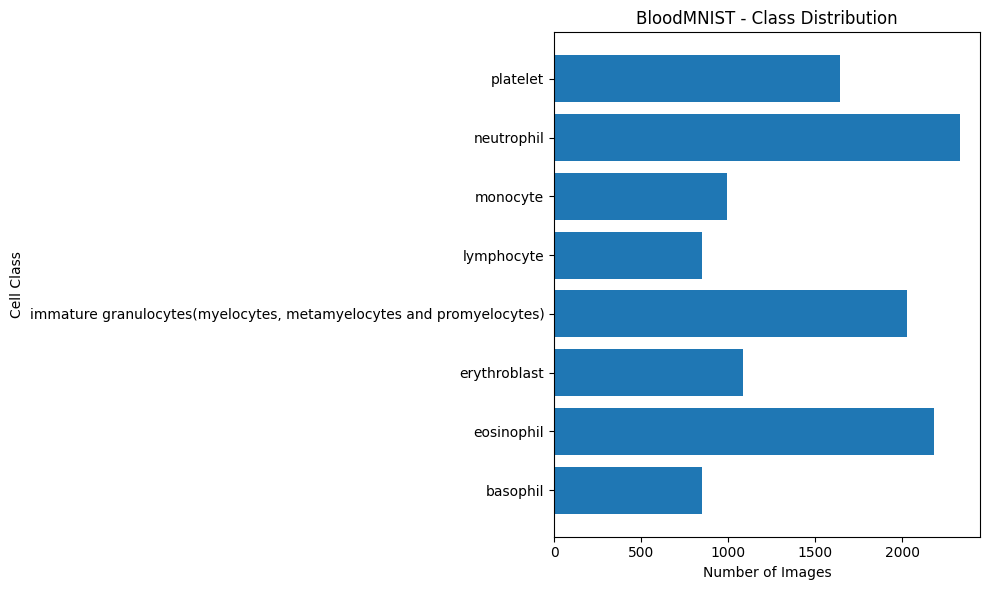

In [5]:
plt.figure(figsize=(10, 6))

plt.barh(
    distribution["Class"],
    distribution["Count"]
)

plt.title("BloodMNIST - Class Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Cell Class")

plt.tight_layout()
plt.show()

In [6]:
distribution["Percentage"] = (
    distribution["Count"] / len(train_dataset) * 100
).round(2)

print(distribution)

                                               Class  Count  Percentage
0                                           basophil    852        7.12
1                                         eosinophil   2181       18.24
2                                       erythroblast   1085        9.07
3  immature granulocytes(myelocytes, metamyelocyt...   2026       16.94
4                                         lymphocyte    849        7.10
5                                           monocyte    993        8.30
6                                         neutrophil   2330       19.48
7                                           platelet   1643       13.74


In [7]:
max_class = distribution.loc[distribution["Count"].idxmax()]
min_class = distribution.loc[distribution["Count"].idxmin()]

imbalance_ratio = max_class["Count"] / min_class["Count"]

print("Most frequent class:", max_class["Class"])
print("Least frequent class:", min_class["Class"])

print("Imbalance ratio:", round(imbalance_ratio, 2))

Most frequent class: neutrophil
Least frequent class: lymphocyte
Imbalance ratio: 2.74


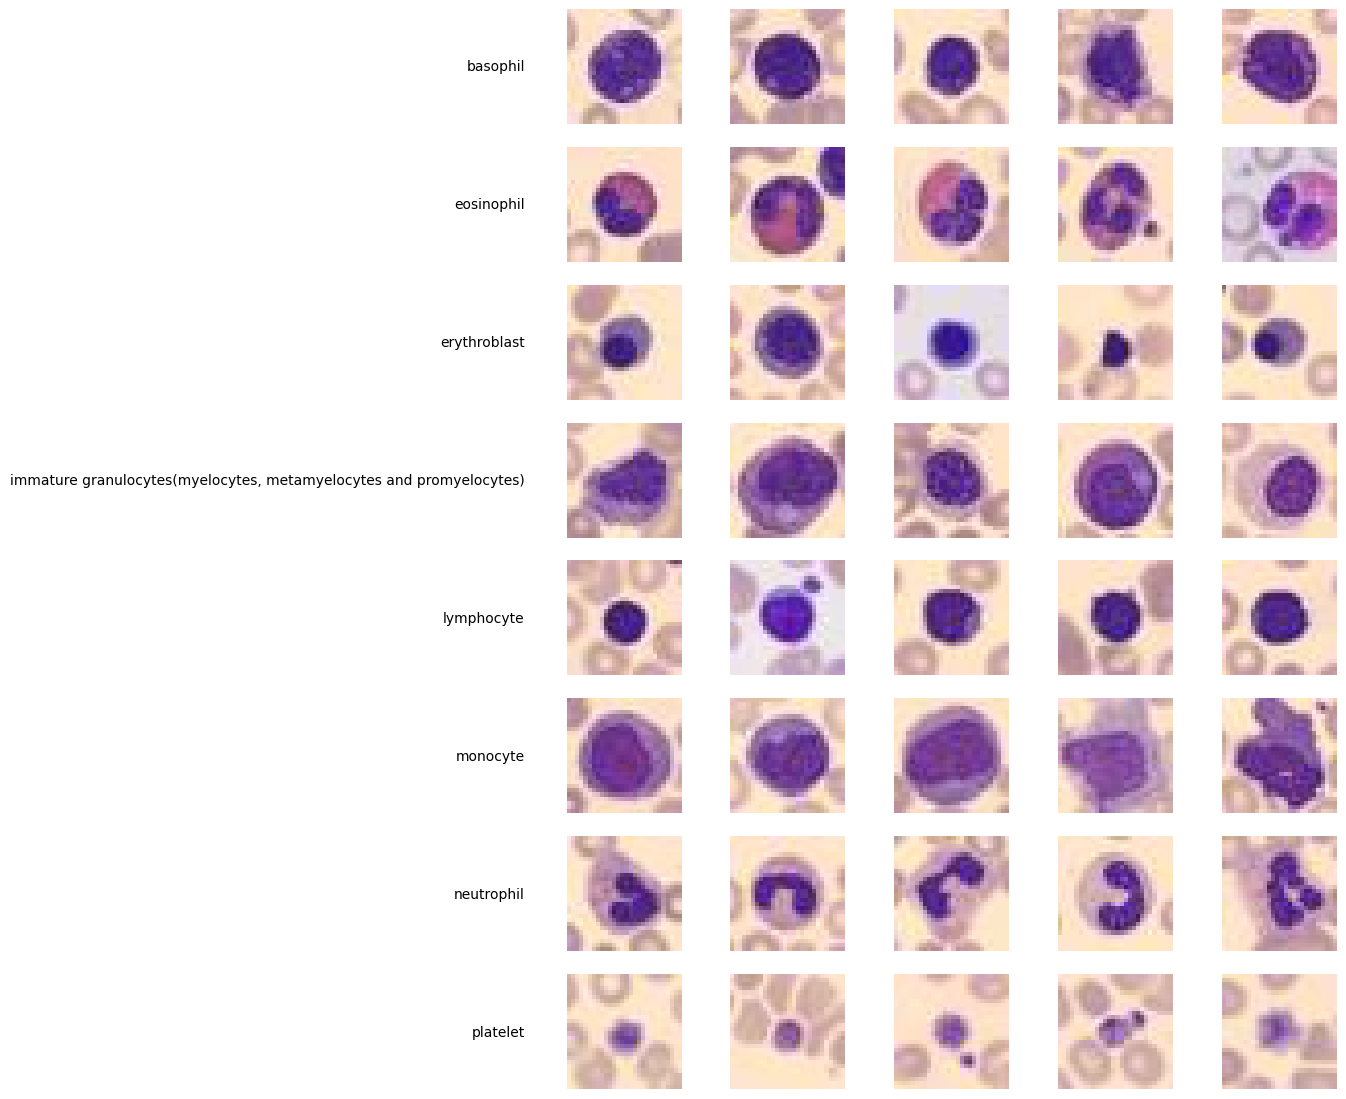

In [ ]:
fig, axes = plt.subplots(8, 5, figsize=(14, 12))

# reserving a wide left margin for the class names
fig.subplots_adjust(left=0.38, right=0.95, top=0.95, bottom=0.05, wspace=0.15, hspace=0.2)

rng = np.random.default_rng(42)

for class_id in range(8):
    indices = np.where(train_labels == class_id)[0]
    selected_indices = rng.choice(
        indices,
        size=5,
        replace=False
    )

    for j, idx in enumerate(selected_indices):
        ax = axes[class_id, j]
        ax.imshow(train_dataset.imgs[idx])
        ax.axis("off")

    bbox = axes[class_id, 0].get_position()
    row_center_y = (bbox.y0 + bbox.y1) / 2

    # placing the class name cleanly on the left side
    fig.text(
        0.36, row_center_y, 
        label_map[class_id], 
        ha='right', 
        va='center', 
        fontsize=10,
        fontweight='medium'
    )

plt.show()

In [16]:
images = train_dataset.imgs

channel_means = images.mean(axis=(0, 1, 2))
channel_stds = images.std(axis=(0, 1, 2))

for i, channel in enumerate(["Red", "Green", "Blue"]):
    print(f"{channel}:")
    print(f"  Mean: {channel_means[i]:.2f}")
    print(f"  Std:  {channel_stds[i]:.2f}")

Red:
  Mean: 202.56
  Std:  54.99
Green:
  Mean: 168.21
  Std:  61.61
Blue:
  Mean: 177.53
  Std:  30.06


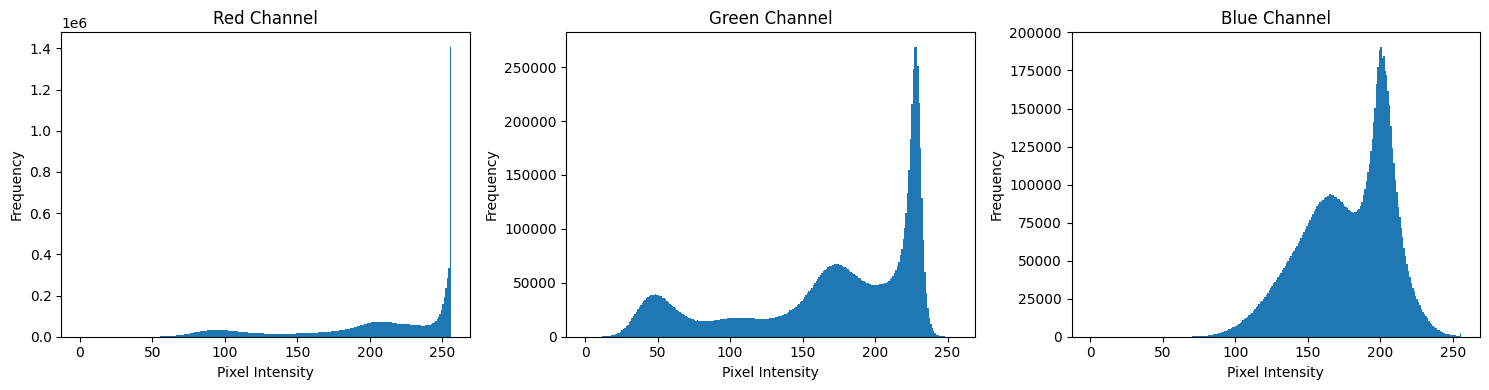

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

channels = ["Red", "Green", "Blue"]

for i, channel in enumerate(channels):

    pixel_values = images[:, :, :, i].ravel()

    axes[i].hist(
        pixel_values,
        bins=256,
        range=(0, 256)
    )

    axes[i].set_title(f"{channel} Channel")
    axes[i].set_xlabel("Pixel Intensity")
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [18]:
import hashlib

datasets = {
    "train": train_dataset,
    "validation": val_dataset,
    "test": test_dataset
}

records = []

for split_name, dataset in datasets.items():

    labels = dataset.labels.squeeze()

    for idx, (image, label) in enumerate(
        zip(dataset.imgs, labels)
    ):

        # Convert image into bytes and calculate SHA-256 hash
        image_hash = hashlib.sha256(
            image.tobytes()
        ).hexdigest()

        records.append({
            "split": split_name,
            "index": idx,
            "label_id": int(label),
            "label_name": label_map[int(label)],
            "hash": image_hash
        })

image_index = pd.DataFrame(records)

print("Total images analyzed:", len(image_index))
image_index.head()

Total images analyzed: 17092


,split,index,label_id,label_name,hash
0,train,0,7,platelet,5a078cb7d2ccdc4d08c33aed60e585fb5821a9d48b43ef...
1,train,1,3,"immature granulocytes(myelocytes, metamyelocyt...",899856124d2613175132607ae1082169570660549a0049...
2,train,2,6,neutrophil,991105c5173ee78329995d14e0771657b6d11c22f8f34b...
3,train,3,6,neutrophil,624ca5d9e3b5b93381f6072459c501856abf775465f17e...
4,train,4,7,platelet,adff53bafd8d2fb5825f7398cdd9bd777818f96ba610ee...


In [19]:
within_split = (
    image_index
    .groupby(["split", "hash"])
    .size()
    .reset_index(name="copies")
)

duplicates_within = within_split[
    within_split["copies"] > 1
]

print("Duplicate groups within splits:")
print(duplicates_within)

print(
    "\nTotal additional copies:",
    (duplicates_within["copies"] - 1).sum()
)

Duplicate groups within splits:
       split                                               hash  copies
3491   train  01768683829328baf9ae989653d23be70204b365a329f9...       2
5268   train  28565e637a55816240af4991aff839f9598359f5d300d6...       2
6723   train  483db15cb9fee3826301a3606d27ff052315fd26f4a031...       2
8569   train  6fb4cbad6ed42059a30600f33abb95c5fadc47e9a757b4...       2
8995   train  78766dfaaf637086dc37416a9c43ae15cc4deb0f1a7703...       2
9866   train  8bda18d5d9f48156678b9cc56c277cde74f473a35a3aae...       2
10046  train  8f6512056cc578cb9afda760404cb35b42a16d0f80ac80...       2
15216  train  fc4856f5fa7092b777d5b68b9e0957dc41a29a75d5e87a...       2

Total additional copies: 8


In [20]:
split_summary = (
    image_index
    .groupby("hash")
    .agg(
        copies=("hash", "size"),
        split_count=("split", "nunique"),
        splits=("split", lambda x: list(set(x))),
        label_count=("label_id", "nunique")
    )
    .reset_index()
)

cross_split_duplicates = split_summary[
    split_summary["split_count"] > 1
]

print(cross_split_duplicates)

print(
    "Number of cross-split duplicate images:",
    len(cross_split_duplicates)
)

                                                    hash  copies  split_count  \
317    04c46b18e78dd05152cbdbd3a6216915b254fe8e3295e4...       2            2   
3011   2e1357eaa909eed4d6cfacf5f6c0b32e8836e4aca62a87...       2            2   
5236   4f9c9fea816a7864d5fb9b94bfe8e81930b2678620002d...       2            2   
9968   96b8d45879d3c142ba5992729fadf12ea2a3505120e08f...       2            2   
11092  a7b330090d9bbe1a92974e3312a370f3a4f88bcf91fc6d...       2            2   
11194  a960b856e21f81c76495535186edbc147535519e55681b...       2            2   
11332  ab8f2e7af9cbf8bb7c27a90a31f16b05ff0015ad7e536a...       2            2   
11544  ae83c90763591abd564c87c5e9ad8bbc8b7849b9389e2e...       2            2   
13723  ce33176f168412e7c1c1600c08de0db62016ceca964ca5...       2            2   

                    splits  label_count  
317     [validation, test]            1  
3011         [train, test]            2  
5236         [train, test]            1  
9968   [train, valida

In [21]:
label_conflicts = split_summary[
    (split_summary["copies"] > 1) &
    (split_summary["label_count"] > 1)
]

print(label_conflicts)

print(
    "Number of conflicting images:",
    len(label_conflicts)
)

                                                   hash  copies  split_count  \
3011  2e1357eaa909eed4d6cfacf5f6c0b32e8836e4aca62a87...       2            2   

             splits  label_count  
3011  [train, test]            2  
Number of conflicting images: 1


In [22]:
conflicting_hashes = label_conflicts["hash"].tolist()

conflict_details = (
    image_index[
        image_index["hash"].isin(conflicting_hashes)
    ]
    .sort_values(["hash", "split"])
)

display(
    conflict_details[
        ["split", "index", "label_id", "label_name"]
    ]
)

,split,index,label_id,label_name
16797,test,3126,6,neutrophil
1018,train,1018,1,eosinophil


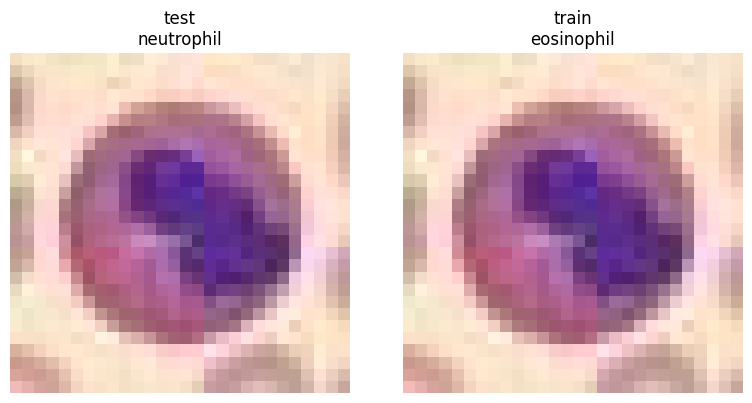

In [23]:
fig, axes = plt.subplots(1, len(conflict_details), figsize=(8, 4))

for ax, row in zip(axes, conflict_details.itertuples(index=False)):
    dataset = datasets[row.split]

    ax.imshow(dataset.imgs[row.index])
    ax.set_title(f"{row.split}\n{row.label_name}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:
# identify the same hashes
conflicting_hashes = set(label_conflicts["hash"])

split_priority = {
    "test": 0,
    "validation": 1,
    "train": 2
}

clean_index = image_index.copy()

# clean the duplicates
clean_index = clean_index[
    ~clean_index["hash"].isin(conflicting_hashes)
]

clean_index["_priority"] = clean_index["split"].map(split_priority)

clean_index = (
    clean_index
    .sort_values(["hash", "_priority", "index"])
    .drop_duplicates(subset="hash", keep="first")
    .drop(columns="_priority")
    .sort_values(["split", "index"])
    .reset_index(drop=True)
)

print("Original images:", len(image_index))
print("Clean images:", len(clean_index))

print("\nImages per split after cleaning:")
print(clean_index.groupby("split").size())

Original images: 17092
Clean images: 17074

Images per split after cleaning:
split
test           3420
train         11943
validation     1711
dtype: int64


In [26]:
clean_datasets = {}

for split_name, dataset in datasets.items():

    indices = clean_index.loc[
        clean_index["split"] == split_name, "index"
    ].to_numpy(dtype=int)

    images = dataset.imgs[indices]
    labels = dataset.labels.squeeze()[indices]

    clean_datasets[split_name] = {
        "images": images,
        "labels": labels
    }

#everything to numpy for machine learning 

X_train = clean_datasets["train"]["images"]
y_train = clean_datasets["train"]["labels"]

X_val = clean_datasets["validation"]["images"]
y_val = clean_datasets["validation"]["labels"]

X_test = clean_datasets["test"]["images"]
y_test = clean_datasets["test"]["labels"]

In [27]:
for split_name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(f"{split_name}:")
    print("  Images:", X.shape)
    print("  Labels:", y.shape)
    print("  Data type:", X.dtype)
    print()

Train:
  Images: (11943, 28, 28, 3)
  Labels: (11943,)
  Data type: uint8

Validation:
  Images: (1711, 28, 28, 3)
  Labels: (1711,)
  Data type: uint8

Test:
  Images: (3420, 28, 28, 3)
  Labels: (3420,)
  Data type: uint8



In [28]:
clean_class_counts = (
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)

clean_distribution = pd.DataFrame({
    "Class": [
        label_map[i] for i in clean_class_counts.index
    ],
    "Count": clean_class_counts.values
})

clean_distribution["Percentage"] = (
    clean_distribution["Count"]
    / len(y_train)
    * 100
)

display(clean_distribution)

,Class,Count,Percentage
0,basophil,846,7.083647
1,eosinophil,2175,18.211505
2,erythroblast,1085,9.084820
3,"immature granulocytes(myelocytes, metamyelocyt...",2023,16.938793
4,lymphocyte,849,7.108767
5,monocyte,992,8.306121
6,neutrophil,2330,19.509336
7,platelet,1643,13.757012


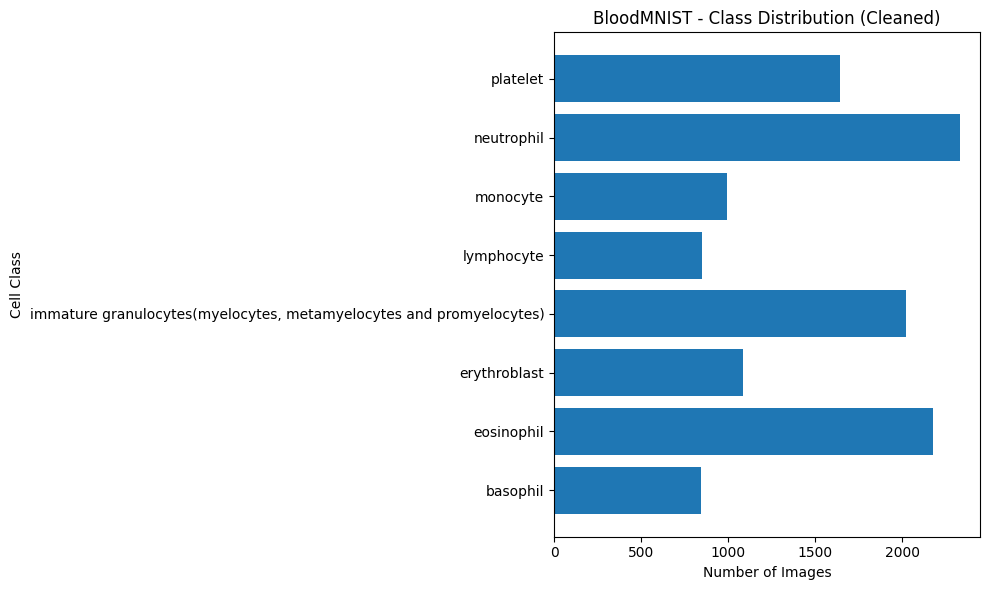

In [29]:
plt.figure(figsize=(10, 6))

plt.barh(
    clean_distribution["Class"],
    clean_distribution["Count"]
)

plt.title("BloodMNIST - Class Distribution (Cleaned)")
plt.xlabel("Number of Images")
plt.ylabel("Cell Class")

plt.tight_layout()
plt.show()

In [30]:
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    PROCESSED_DIR / "bloodmnist_cleaned.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    class_names=np.array([label_map[i] for i in range(8)])
)

print("Cleaned datasets saved successfully!")

Cleaned datasets saved successfully!
